Install Packages and Set Up the Data

In [1]:
# Install these packages with the command below to run the code
# pip install pandas seaborn matplotlib

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df = pd.read_csv("../Data/transformed_study_data.csv")

Static Visualization Implementation

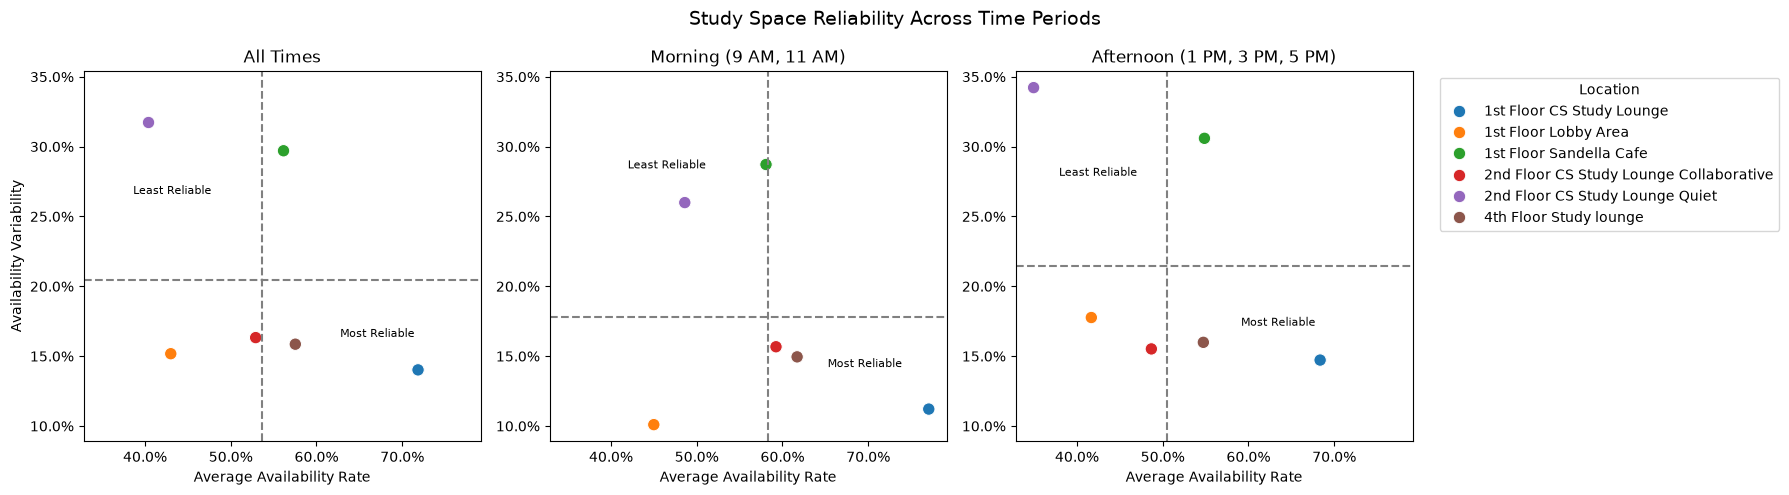

In [2]:
def assign_time_period(time):
    if time in ["9:00", "11:00"]:
        return "Morning"
    else:
        return "Afternoon"

df["time_period"] = df["time"].astype(str).apply(assign_time_period)

# ALL TIMES
all_data = (
    df.groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

# MORNING
morning_data = (
    df[df["time_period"] == "Morning"]
      .groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

# AFTERNOON
afternoon_data = (
    df[df["time_period"] == "Afternoon"]
      .groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

# QUADRANT REFERENCE VALUES
all_x = all_data["avg_availability"].mean()
all_y = all_data["availability_std"].mean()

morning_x = morning_data["avg_availability"].mean()
morning_y = morning_data["availability_std"].mean()

afternoon_x = afternoon_data["avg_availability"].mean()
afternoon_y = afternoon_data["availability_std"].mean()

# CREATE STATIC SMALL MULTIPLES
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# ALL TIMES
sns.scatterplot(
    data=all_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=80,
    ax=axes[0]
)
axes[0].set_title("All Times")
axes[0].set_xlabel("Average Availability Rate")
axes[0].set_ylabel("Availability Variability")
axes[0].axvline(all_x, linestyle="--", color="gray")
axes[0].axhline(all_y, linestyle="--", color="gray")
axes[0].text(
    all_x * 1.17,
    all_y * 0.8,
    "Most Reliable",
    fontsize=8,
)
axes[0].text(
    all_x * 0.72,
    all_y * 1.3,
    "Least Reliable",
    fontsize=8,
)

# MORNING
sns.scatterplot(
    data=morning_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=80,
    ax=axes[1]
)
axes[1].set_title("Morning (9 AM, 11 AM)")
axes[1].set_xlabel("Average Availability Rate")
axes[1].set_ylabel("Availability Variability")
axes[1].axvline(morning_x, linestyle="--", color="gray")
axes[1].axhline(morning_y, linestyle="--", color="gray")
axes[1].text(
    morning_x * 1.12,
    morning_y * 0.8,
    "Most Reliable",
    fontsize=8
)
axes[1].text(
    morning_x * 0.72,
    morning_y * 1.6,
    "Least Reliable",
    fontsize=8
)

# AFTERNOON
sns.scatterplot(
    data=afternoon_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=80,
    ax=axes[2]
)
axes[2].set_title("Afternoon (1 PM, 3 PM, 5 PM)")
axes[2].set_xlabel("Average Availability Rate")
axes[2].set_ylabel("Availability Variability")
axes[2].axvline(afternoon_x, linestyle="--", color="gray")
axes[2].axhline(afternoon_y, linestyle="--", color="gray")
axes[2].text(
    afternoon_x * 1.17,
    afternoon_y * 0.8,
    "Most Reliable",
    fontsize=8
)
axes[2].text(
    afternoon_x * 0.75,
    afternoon_y * 1.3,
    "Least Reliable",
    fontsize=8
)

# FORMAT AXES
for ax in axes:
    ax.xaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )
    ax.yaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )

# Force y tick labels to appear on all plots
for ax in axes:
    ax.tick_params(axis="y", labelleft=True)

# Remove duplicate legends
axes[0].get_legend().remove()
axes[1].get_legend().remove()

# Keep one legend
axes[2].legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.suptitle(
    "Study Space Reliability Across Time Periods",
    fontsize=14
)

plt.tight_layout()
plt.show()

Install Package

In [3]:
# Install this package with the command below to run the code
# pip install plotly

import plotly.graph_objects as go

Interactive Visualization Implementation

In [5]:
# pip install --upgrade nbformat

locations = all_data["location"].tolist()

color_map = {
    "1st Floor CS Study Lounge": "#1f77b4",
    "1st Floor Lobby Area": "#ff7f0e",
    "1st Floor Sandella Cafe": "#2ca02c",
    "2nd Floor CS Study Lounge Collaborative": "#d62728",
    "2nd Floor CS Study Lounge Quiet": "#9467bd",
    "4th Floor Study lounge": "#8c564b"
}

fig = go.Figure()


# CREATE ONE TRACE PER LOCATION
for location in locations:

    row = all_data[
        all_data["location"] == location
    ].iloc[0]

    fig.add_trace(
        go.Scatter(
            x=[row["avg_availability"]],
            y=[row["availability_std"]],
            mode="markers",
            name=location,
            marker=dict(
                size=8,
                color=color_map[location]
            ),
            customdata=[[
                row["location"]
            ]],
            hovertemplate=
            "<b>%{customdata[0]}</b><br><br>"
            "Average Availability: %{x:.1%}<br>"
            "Availability Variability: %{y:.1%}<br>"
            "<extra></extra>"
        )
    )


# CREATE DROPDOWN DATA
all_x = []
all_y = []
all_custom = []

morning_x = []
morning_y = []
morning_custom = []

afternoon_x = []
afternoon_y = []
afternoon_custom = []

for location in locations:

    all_row = all_data[
        all_data["location"] == location
    ].iloc[0]

    morning_row = morning_data[
        morning_data["location"] == location
    ].iloc[0]

    afternoon_row = afternoon_data[
        afternoon_data["location"] == location
    ].iloc[0]

    all_x.append(all_row["avg_availability"])
    all_y.append(all_row["availability_std"])
    all_custom.append([
        all_row["location"]
    ])

    morning_x.append(morning_row["avg_availability"])
    morning_y.append(morning_row["availability_std"])
    morning_custom.append([
        morning_row["location"]
    ])

    afternoon_x.append(afternoon_row["avg_availability"])
    afternoon_y.append(afternoon_row["availability_std"])
    afternoon_custom.append([
        afternoon_row["location"],
    ])


# DROPDOWN
fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="All Times",
                    method="restyle",
                    args=[
                        {
                            "x": [[x] for x in all_x],
                            "y": [[y] for y in all_y],
                            "customdata": [[c] for c in all_custom]
                        }
                    ]
                ),
                dict(
                    label="Morning (9 AM, 11 AM)",
                    method="restyle",
                    args=[
                        {
                            "x": [[x] for x in morning_x],
                            "y": [[y] for y in morning_y],
                            "customdata": [[c] for c in morning_custom]
                        }
                    ]
                ),
                dict(
                    label="Afternoon (1 PM, 3 PM, 5 PM)",
                    method="restyle",
                    args=[
                        {
                            "x": [[x] for x in afternoon_x],
                            "y": [[y] for y in afternoon_y],
                            "customdata": [[c] for c in afternoon_custom]
                        }
                    ]
                )
            ],
            direction="down",
            x=0.95,
            y=1.18
        )
    ]
)


# QUADRANTS
avg_x = all_data["avg_availability"].mean()
avg_y = all_data["availability_std"].mean()

fig.add_vline(
    x=avg_x,
    line_dash="dash",
    line_color="gray"
)

fig.add_hline(
    y=avg_y,
    line_dash="dash",
    line_color="gray"
)

fig.add_annotation(
    x=avg_x * 1.2,
    y=avg_y * 0.85,
    text="<b>Most Reliable</b>",
    showarrow=False
)

fig.add_annotation(
    x=avg_x * 0.87,
    y=avg_y * 1.38,
    text="<b>Least Reliable</b>",
    showarrow=False
)


# LAYOUT
fig.update_layout(
    title="Reliability of Seat Availability",
    xaxis_title="Average Availability Rate",
    yaxis_title="Availability Variability (Standard Deviation)",
    legend_title_text="Location"
)

fig.update_xaxes(tickformat=".0%")
fig.update_yaxes(tickformat=".0%")

fig.show()